# Briefing
Esse notebook tem como objetivo treinar um modelo de classificação de eventos sonoros. Utilizou o dataset **UrbanSound8K**, pré-separado em 10 folds, com 10 categorias de eventos sonoros.

Utilizou-se um Multilayer Perceptron para classificar o áudio com base no seu MFCC, um tipo de espectrograma específico capaz de comprimir a informação tempo-frequência em poucos `bins` espectrais.

# Importando tudo

In [12]:
# !!Panic Button
# Deletar checkpoints
## !rm -rf checkpoints
## !mkdir checkpoints
# print('done')


# import os
# os._exit(0)


done


In [19]:
from IPython.display import clear_output

!git clone https://github.com/y7kko/COM804-Classifier.git ykk_repo
!git -C ./ykk_repo/ pull
!pip install git+https://github.com/soundata/soundata.git
!pip install torch-audiomentations
!pip install git+https://github.com/iver56/audiomentations.git


clear_output()
import sys
import os

sys.path.append('./ykk_repo/')
os.environ['YKK_NOCHDIR'] = '1'
os.environ['US8K_PATH'] = './data/urbansound8k'

import ykk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import optuna
ykk.urban8k(root_path=os.environ['US8K_PATH']).download_dataset()
import time
import copy
from torchaudio import transforms
from pathlib import Path
Path('./checkpoints/').mkdir(parents=True, exist_ok=True)
print('Done, check console for more details')

_t0= None
_t1 = None

def tic():
    global _t0
    _t0 = time.time()

def toc():
    global _t1,_t0
    _t1 = time.time()
    dt =_t1 - _t0
    _t0,_t1 = None,None
    return dt

Done, check console for more details


# Declarando

## Dataset importer

In [5]:
def get_data(val_fold,fs,transform):
    """Splits dataset"""
    train_fld = [f for f in range(1, 11) if f != val_fold]
    test_fld = train_fld[0]
    train_fld = train_fld[1:]
    
    valid_data = ykk.urban8k(augmentation= False, fs=fs, filter_folds = val_fold)
    test_data  = ykk.urban8k(augmentation= False, fs=fs, filter_folds = test_fld)
    train_data = ykk.urban8k(augmentation= False,  fs=fs, filter_folds = train_fld)

    # np.random.seed(0)
    for _data in [train_data,valid_data,test_data]:
            _data.set_transform(transform)
            _data.cache_features()
    return train_data,valid_data,test_data


def get_skdata(val_fold,fs,transform):
    """Converte da convenção do torch para a convenção do SKLearn(random forest)"""
    train_data,valid_data,test_data = get_data(val_fold,fs,transform)
    fold_data = {}
    for split,d in zip(['train','validation','test'],[train_data,valid_data,test_data]):
        features = (d.cached_features[0]
                      .numpy()
                      .squeeze()
                   )
        fold_data[split] = {
            'X': (features.reshape(len(d),-1)),
            # 'X': features,
            'y': (d.cached_labels.numpy().squeeze())
        }
    return fold_data

## Parâmetros
Foi utilizado o MFCC transform para realizar extração das features. Embora alguns estudos apontem melhores resultados com STFT ou log-mel, o modelo foi treinado na CPU, e a MFCC oferece dados com menos dimensões.

- `fs`: Frequência de amostragem do sinal
- `mel_kw`: Parâmetros do espectrograma
- `n_mfcc`: número de componentes de frequência por frame de tempo

Nota: para simplificar, o tamanho da input layer foi calculado realizando a extração de features, mas há forma analítica de calcular.

In [6]:
fs = 22050
transform = nn.Sequential(
    transforms.MelSpectrogram(fs,n_fft=512,hop_length=512,n_mels=60,),
    transforms.AmplitudeToDB(stype="power", top_db=80)
)
_d = ykk.urban8k(fs=fs)
_d.set_transform(transform)
input_shape = list((_d[0][0]).shape)
print(f'input shape: {input_shape} ({np.prod(input_shape)})')

input shape: [1, 60, 130] (7800)


(60, 130)


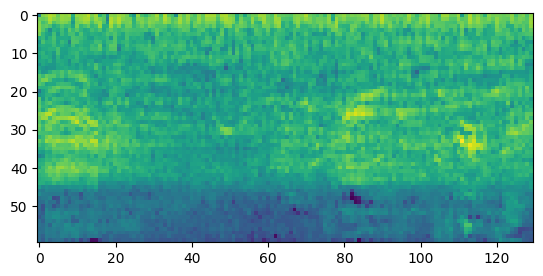

In [7]:
import matplotlib.pyplot as plt
spk = np.array(_d[1][0].numpy().squeeze())
print(spk.shape)
plt.subplot(111)
plt.imshow(spk)


In [11]:
data = get_skdata(1,fs,transform)

Caching features (0/0):   0%|          | 0/6971 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/873 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/888 [00:00<?, ?it/s]

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, ConfusionMatrixDisplay)


In [30]:
def rf_gridsearch(data,estimators,depth,samples):
    accuracies = np.zeros([len(estimators),len(depth),len(spl_split)])
    for i, n_estimators in enumerate(estimators):
        for j, max_depth in enumerate(depth):
            for k, min_samples in enumerate(samples):
                rf = RandomForestClassifier(random_state=42, 
                                            n_jobs=-1,
                                            n_estimators=n_estimators,
                                            max_depth=max_depth,
                                            min_samples_split=min_samples
                                           )
                rf.fit(data['train']['X'], data['train']['y'])
                tic()
                y_pred = rf.predict(data['validation']['X'])
                print(f'elapsed time:{toc()}')
                acc_base = accuracy_score(data['validation']['y'], y_pred)
                print(f"Acurácia baseline: {acc_base:.4f}")
                accuracies[i,j,k] = acc_base
    return accuracies

In [31]:
estimators = [100, 200, 300]
depth = [None, 10, 20]
spl_split = [2, 5]

acc = []
for fold in [1,3,5,9]:
    data = get_skdata(1,fs,transform)
    acc_grid = rf_gridsearch(data,estimators,depth,spl_split)
    acc.append(acc_grid)
acc = np.asarray(acc)


Caching features (0/0):   0%|          | 0/6971 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/873 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/888 [00:00<?, ?it/s]

elapsed time:0.06655454635620117
Acurácia baseline: 0.5338
elapsed time:0.04963970184326172
Acurácia baseline: 0.5372
elapsed time:0.05075645446777344
Acurácia baseline: 0.5384
elapsed time:0.06303095817565918
Acurácia baseline: 0.5418
elapsed time:0.06351161003112793
Acurácia baseline: 0.5418
elapsed time:0.06163477897644043
Acurácia baseline: 0.5395
elapsed time:0.39074039459228516
Acurácia baseline: 0.5475
elapsed time:0.12026286125183105
Acurácia baseline: 0.5384
elapsed time:0.1033470630645752
Acurácia baseline: 0.5338
elapsed time:0.11782407760620117
Acurácia baseline: 0.5384
elapsed time:0.09275603294372559
Acurácia baseline: 0.5521
elapsed time:0.11939811706542969
Acurácia baseline: 0.5521
elapsed time:0.14797544479370117
Acurácia baseline: 0.5452
elapsed time:0.1607203483581543
Acurácia baseline: 0.5464
elapsed time:0.14558887481689453
Acurácia baseline: 0.5326
elapsed time:0.14934468269348145
Acurácia baseline: 0.5384


KeyboardInterrupt: 

In [33]:
acc = np.zeros(10)
for i, fold in enumerate(range(1,11)):
    print(f'fold {fold}')
    data = get_skdata(1,fs,transform)
    rf = RandomForestClassifier(random_state=42, n_jobs=-1, 
                                n_estimators=200,
                                max_depth=20,
                               )
    rf.fit(data['train']['X'], data['train']['y'])
    tic()
    y_pred = rf.predict(data['validation']['X'])
    print(f'elapsed time:{toc()}')
    acc_base = accuracy_score(data['validation']['y'], y_pred)
    print(f"Acurácia baseline: {acc_base:.4f}")
    acc[i] = acc_base

fold 1


Caching features (0/0):   0%|          | 0/6971 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/873 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/888 [00:00<?, ?it/s]

elapsed time:0.10538029670715332
Acurácia baseline: 0.5521
fold 2


Caching features (0/0):   0%|          | 0/6971 [00:00<?, ?it/s]

... (31 outputs left out)

Caching features (0/0):   0%|          | 0/6971 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/873 [00:00<?, ?it/s]

Caching features (0/0):   0%|          | 0/888 [00:00<?, ?it/s]

elapsed time:0.09458494186401367
Acurácia baseline: 0.5521


In [ ]:
from tqdm.auto import tqdm
import time
hours = 4
for i in tqdm(range(hours*60*60)):
    time.sleep(1)    